# Choropleth Plotting Examples

Two examples of the [`laser.core.plotting.choropleth`](../src/laser/core/plotting.py)
helper for rendering spatial maps of per-region quantities:

1. **Single choropleth** — plot the initial population of Mali's admin-2 regions from
   the `MLI_admin2.gpkg` GeoPackage bundled next to this notebook.
2. **3-column × 2-row grid** — six panels of stochastic per-patch values, showing how
   to compose `choropleth()` with a Matplotlib subplot grid via the `ax=` parameter.


In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

from laser.core.plotting import choropleth


## (a) Single choropleth — Mali admin-2 population

`MLI_admin2.gpkg` (bundled next to this notebook) contains 160 admin-2 regions of
Mali with a `population` column. Populations span several orders of magnitude across
regions, so we plot on a log scale (`log=True` renders `log10(1 + value)`).


loaded 160 regions; columns = ['adm2_name', 'dot_name', 'adm2_pcode', 'name', 'nodeid', 'population', 'geometry']
population: min=832  max=2,282,896  median=58,502


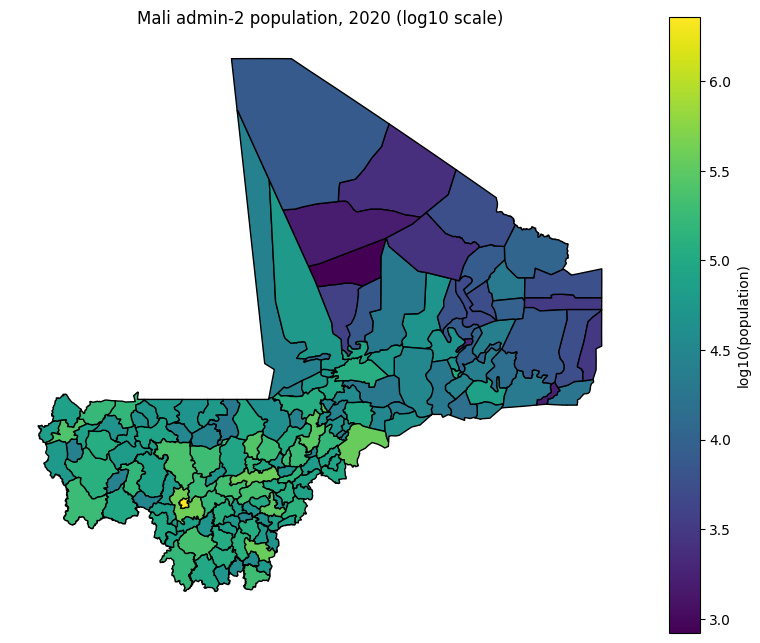

In [2]:
gpkg = Path.cwd() / "MLI_admin2.gpkg"
gdf = gpd.read_file(gpkg)
print(f"loaded {len(gdf)} regions; columns = {list(gdf.columns)}")
print(f"population: min={gdf['population'].min():,}  max={gdf['population'].max():,}  median={int(gdf['population'].median()):,}")

choropleth(
    gdf,
    column="population",
    log=True,
    title="Mali admin-2 population, 2020 (log10 scale)",
    legend_label="log10(population)",
    cmap="viridis",
    figsize=(10, 8),
);


## (b) 3×2 grid — stochastic per-patch values

Six independent random draws over the same 160 Mali regions, laid out in a
3-column × 2-row grid. Think of each panel as a different stochastic realization,
scenario, or snapshot in time. The key API pattern is passing an existing Matplotlib
`Axes` into each `choropleth()` call via `ax=` — the helper then draws into that
subplot instead of creating its own figure.

We use `values=...` (rather than `column=...`) to hand `choropleth()` an
array of per-region values that isn't already stored on the GeoPackage; the array
must have one entry per row of `gdf`, in row order.

> **Note on shared scales.** `choropleth()` currently auto-scales its colorbar per
> panel, so raw colors are not directly comparable across panels. Match on rank or
> spatial pattern rather than absolute color. If you need a shared range, pre-normalize
> your values into a common scale, or extend the helper to expose `vmin` / `vmax`.


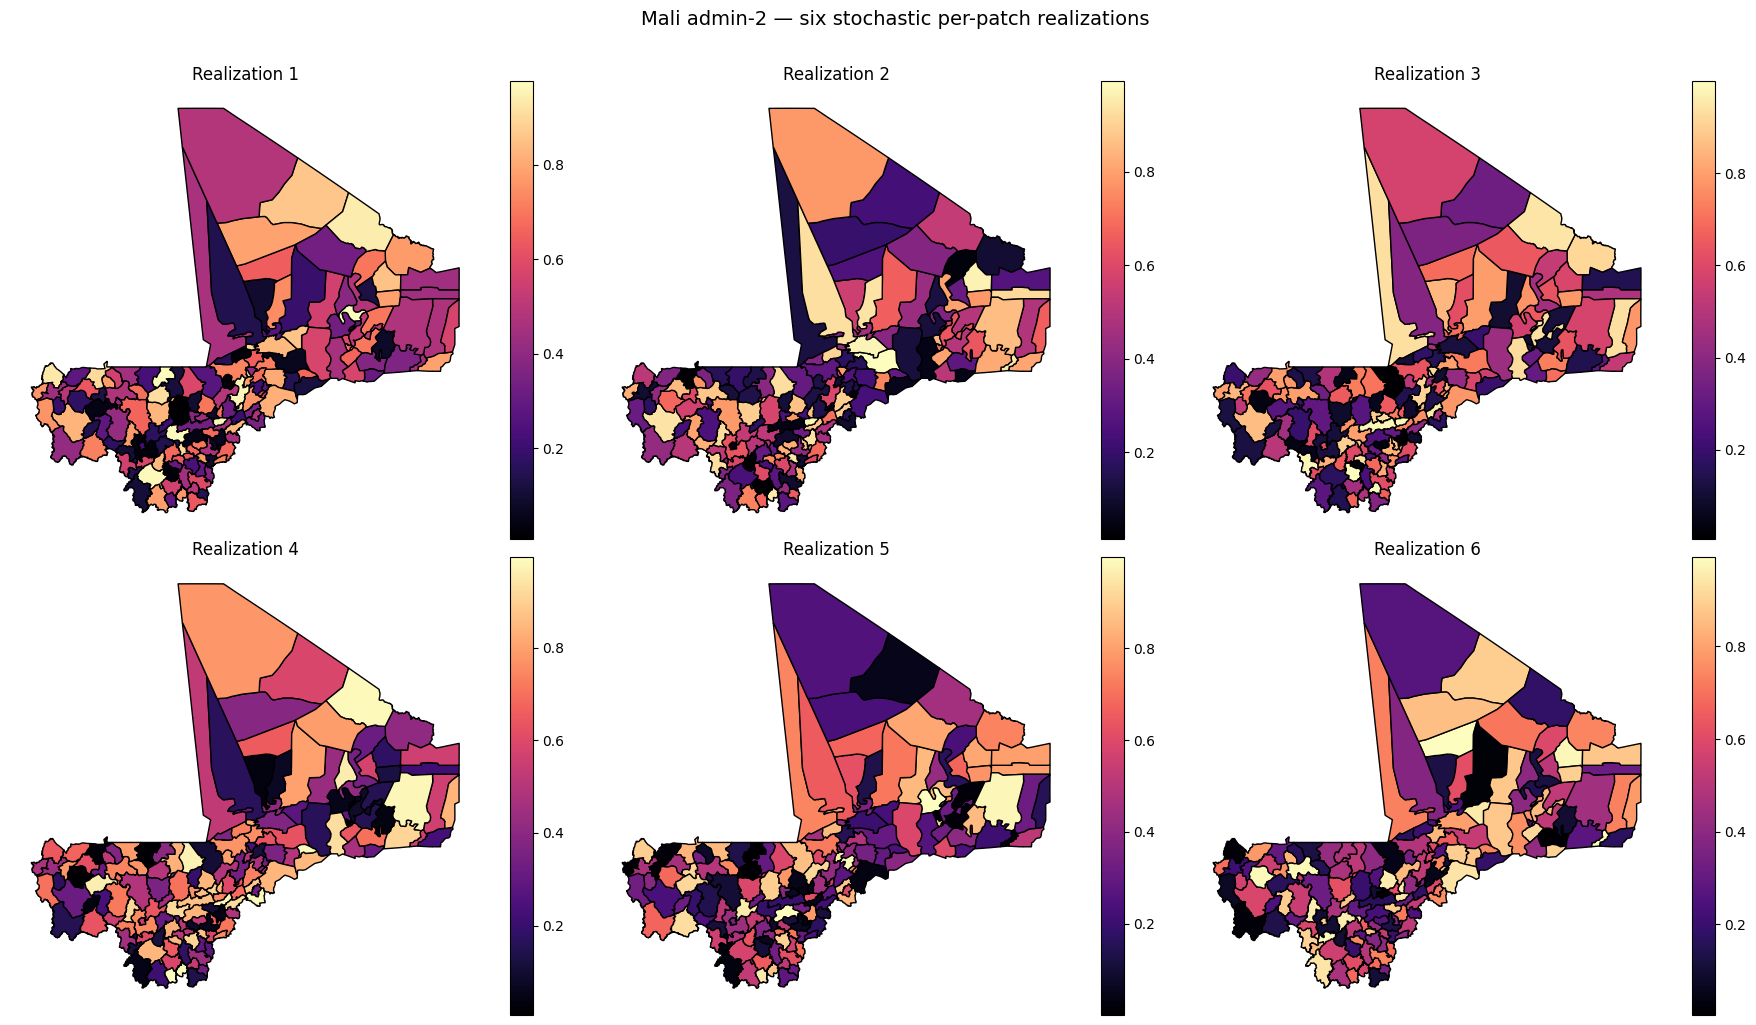

In [3]:
n_patches = len(gdf)
rng = np.random.default_rng(42)

# Six independent per-patch draws — e.g. six stochastic realizations of an attack-rate
# metric, or the same metric evaluated at six different simulation snapshots.
scenarios = [
    ("Realization 1", rng.uniform(0.0, 1.0, n_patches)),
    ("Realization 2", rng.uniform(0.0, 1.0, n_patches)),
    ("Realization 3", rng.uniform(0.0, 1.0, n_patches)),
    ("Realization 4", rng.uniform(0.0, 1.0, n_patches)),
    ("Realization 5", rng.uniform(0.0, 1.0, n_patches)),
    ("Realization 6", rng.uniform(0.0, 1.0, n_patches)),
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (name, values) in zip(axes.flat, scenarios):
    choropleth(
        gdf,
        values=values,
        column="attack_rate",  # attach values under this name (used for the panel title default too)
        title=name,
        legend=True,
        cmap="magma",
        ax=ax,
    )

fig.suptitle("Mali admin-2 — six stochastic per-patch realizations", fontsize=14, y=1.02)
plt.tight_layout()


### Recap

- **Example (a)** uses `column=` to plot an existing GeoPackage column, and `log=True`
  to compress the wide dynamic range of raw population counts.
- **Example (b)** uses `values=` to attach arbitrary per-region data at plot time, and
  `ax=` to compose several panels into a shared figure. Any Matplotlib subplot layout
  works — `plt.subplots(rows, cols)` is the simplest.


## (c) Animated choropleth — sweeping through frames

`animate_choropleth()` renders a sequence of per-region value frames as an animation on
the same regions, with a **shared colorbar** across all frames so absolute colors are
directly comparable (the key win over the 3×2 grid in section (b), whose per-panel
colorbars auto-scale independently).

**File format is inferred from the extension of `output_path`:**

| Extension              | Writer                | External dependency |
| ---------------------- | --------------------- | ------------------- |
| `.gif`                 | `PillowWriter`        | Pillow — already a hard dep of matplotlib. **No extra install.** |
| `.html` / `.htm`       | JS animation embedded in a self-contained HTML file via `to_jshtml()` | None (matplotlib only). **No extra install.** |
| `.mp4` / `.webm` / `.mov` | `FFMpegWriter`        | The `ffmpeg` binary must be on PATH. |

For the built-in scenario, we simulate a synthetic per-patch metric that starts as a
smooth radial pattern and picks up more spatial noise over time — visually easy to
follow across frames.


In [4]:
# Build 24 frames of a synthetic per-patch metric with a shared [0, 1] range.
n_patches = len(gdf)
n_frames = 24

# Static "distance from centroid of Mali" gives a spatial gradient we can modulate.
centroids = gdf.geometry.centroid
cx, cy = centroids.x.mean(), centroids.y.mean()
distance = np.hypot(centroids.x - cx, centroids.y - cy).to_numpy()
distance = (distance - distance.min()) / (distance.max() - distance.min())  # -> [0, 1]

rng = np.random.default_rng(0)
frames = np.empty((n_frames, n_patches), dtype=float)
for t in range(n_frames):
    phase = t / (n_frames - 1)                       # 0 -> 1 over the animation
    noise = rng.uniform(-0.15, 0.15, n_patches)      # spatial noise, more visible later
    frames[t] = np.clip((1 - phase) * (1 - distance) + phase * (distance + noise), 0.0, 1.0)

frame_titles = [f"t = {t:>2d} / {n_frames - 1}" for t in range(n_frames)]
print(f"frames shape = {frames.shape}; range per frame ≈ [{frames.min():.2f}, {frames.max():.2f}]")


frames shape = (24, 160); range per frame ≈ [0.00, 1.00]


/var/folders/fl/_ns4br_j2qxd92vjrgl3t4n00000gn/T/ipykernel_17548/3659943145.py:6: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centroids = gdf.geometry.centroid


### (c.i) Animated GIF (Pillow — no extra install)

The lightest option. Pillow is already required by matplotlib, so this works
out-of-the-box in any environment where the rest of `laser.core.plotting` works.
Small drawback: GIF is limited to 256 colors per frame, which is fine for a viridis
choropleth but can look banded on high-color imagery.


wrote mali_animation.gif (1,616,491 bytes)


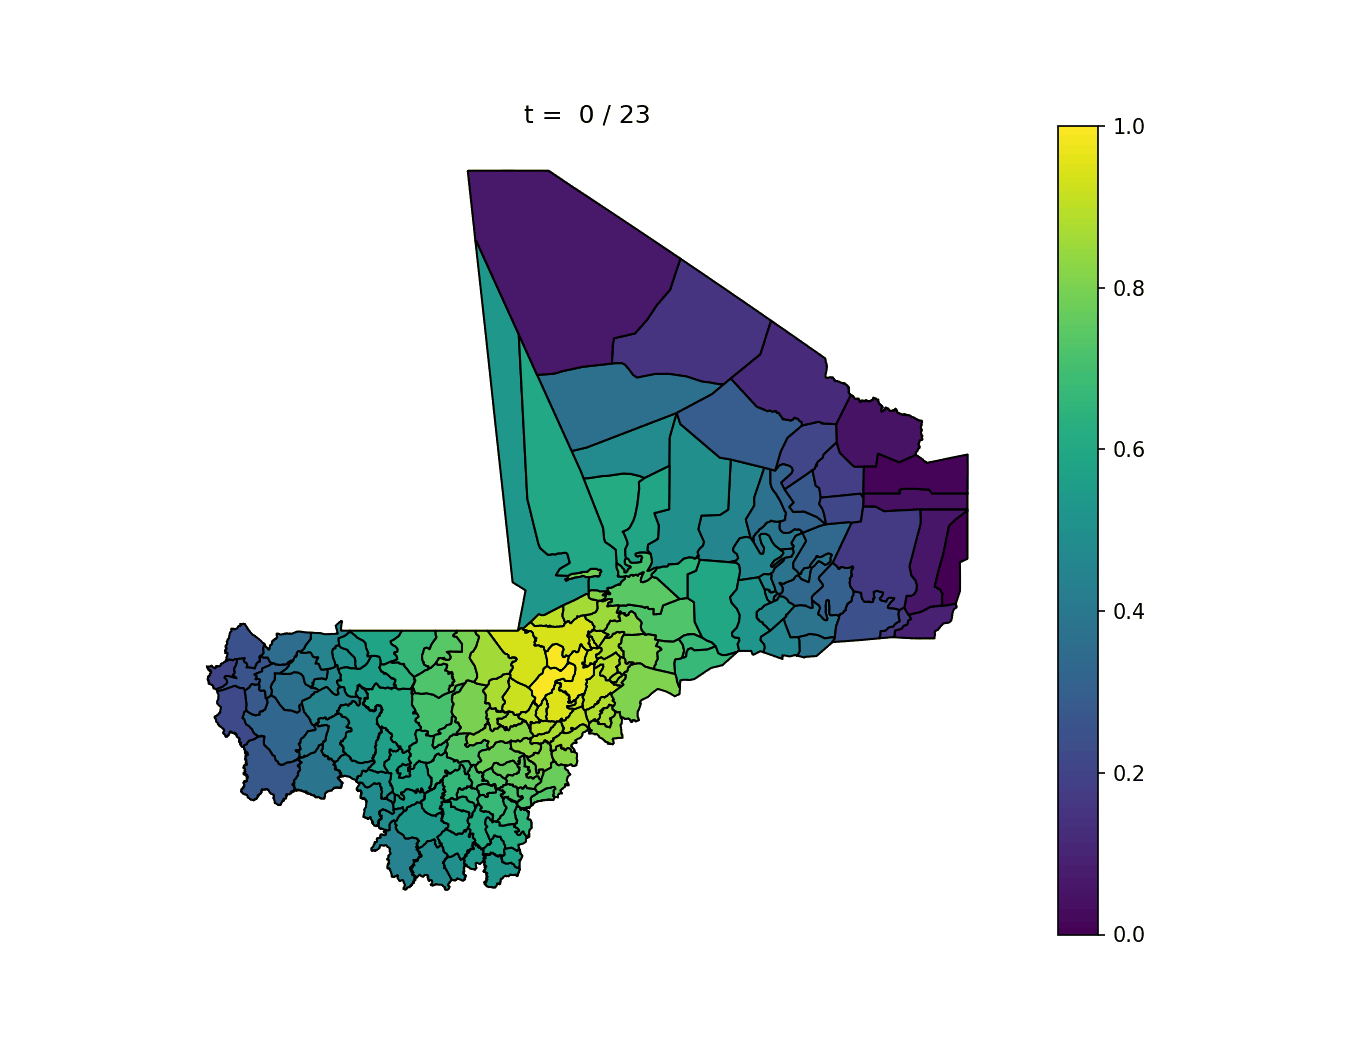

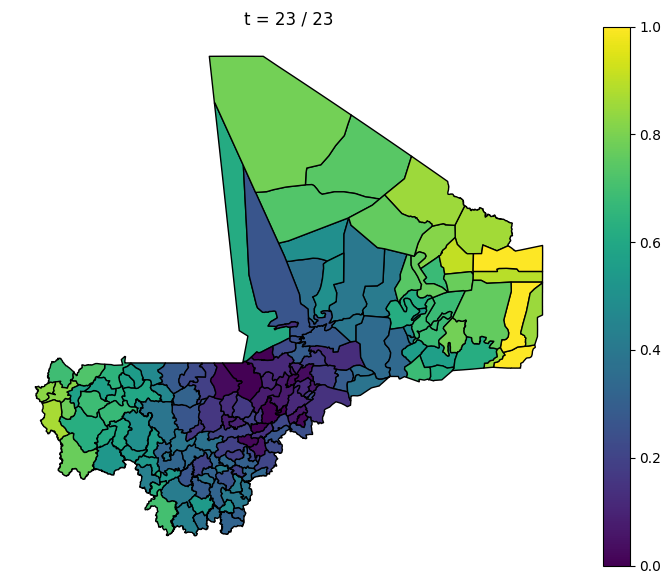

In [5]:
from laser.core.plotting import animate_choropleth
from IPython.display import Image

gif_path = Path.cwd() / "mali_animation.gif"

animate_choropleth(
    gdf,
    frames,
    column="synthetic_metric",
    frame_titles=frame_titles,
    cmap="viridis",
    vmin=0.0,
    vmax=1.0,
    fps=6,
    figsize=(9, 7),
    output_path=gif_path,
)
print(f"wrote {gif_path.name} ({gif_path.stat().st_size:,} bytes)")
Image(filename=str(gif_path))


### (c.ii) HTML5 + JavaScript (matplotlib alone — no extra install)

Best when the audience is Jupyter-based: `to_jshtml()` embeds each frame as a
base64-encoded PNG plus a small JS controller (play / pause / step / speed). No
external tools required; the resulting HTML file is self-contained and playable
in any modern browser.

The cell below both saves an HTML file to disk **and** renders the animation
inline in the notebook by wrapping `anim.to_jshtml()` in `IPython.display.HTML`.


wrote mali_animation.html (3,687,053 bytes)


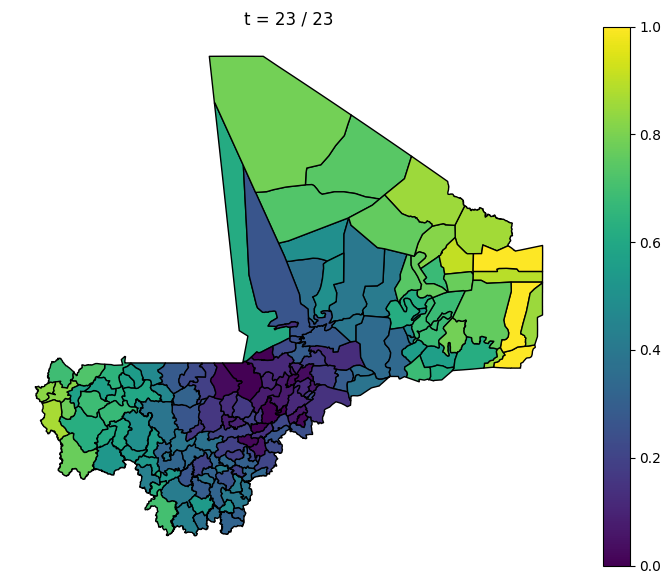

In [6]:
from IPython.display import HTML

html_path = Path.cwd() / "mali_animation.html"

anim = animate_choropleth(
    gdf,
    frames,
    column="synthetic_metric",
    frame_titles=frame_titles,
    cmap="viridis",
    vmin=0.0,
    vmax=1.0,
    fps=6,
    figsize=(9, 7),
    output_path=html_path,
)
print(f"wrote {html_path.name} ({html_path.stat().st_size:,} bytes)")

# Inline preview in the notebook — same JS animation, embedded here.
HTML(anim.to_jshtml(fps=6))


### (c.iii) MP4 via `ffmpeg` — extra install required

For high-quality video (larger frame counts, better compression, embed in slides
that don't render GIF well), MP4 is the natural choice. The trade-off is a
non-Python dependency on the `ffmpeg` binary.

**Extra install steps (choose one for your platform):**

| Platform         | Command                                        |
| ---------------- | ---------------------------------------------- |
| macOS (Homebrew) | `brew install ffmpeg`                          |
| Debian / Ubuntu  | `sudo apt-get install ffmpeg`                  |
| Conda / mamba    | `conda install -c conda-forge ffmpeg`          |
| Windows          | download from <https://ffmpeg.org/download.html> and ensure it's on `PATH` |

Once `ffmpeg` is on your `PATH`, saving MP4 is the same call — just change the
extension:

```python
animate_choropleth(
    gdf,
    frames,
    output_path="mali_animation.mp4",   # extension picks the writer
    fps=30,
    ...
)
```

`animate_choropleth()` checks for the binary before it tries to invoke it and
raises a `RuntimeError` with the install hint above if it's missing — so a
teammate opening this notebook without ffmpeg won't see a cryptic matplotlib
traceback.

The MP4 cell is **not** executed here because the CI runners for `laser.core`
don't ship ffmpeg. Uncomment locally if you want to try it.


In [7]:
# Uncomment to render mali_animation.mp4 (requires ffmpeg on PATH).
#
# mp4_path = Path.cwd() / "mali_animation.mp4"
# animate_choropleth(
#     gdf,
#     frames,
#     column="synthetic_metric",
#     frame_titles=frame_titles,
#     cmap="viridis",
#     vmin=0.0,
#     vmax=1.0,
#     fps=30,
#     figsize=(9, 7),
#     output_path=mp4_path,
# )
# print(f"wrote {mp4_path.name}")


### Recap redux

- **GIF via `PillowWriter`** — zero new dependencies, works everywhere matplotlib does.
  Best default for portable animated output.
- **HTML5 / JS via `to_jshtml()`** — zero new dependencies, best for inline notebook
  playback. Same trick powers `HTML(anim.to_jshtml())` above.
- **MP4 via `FFMpegWriter`** — requires the `ffmpeg` binary; only earn its keep when
  you specifically need MP4/WebM output (long animations, presentation embeds, etc.).

In all three cases the **shared colorbar** (auto-computed global min/max, or explicit
`vmin`/`vmax`) is what makes the animation comparable frame-to-frame — it's the
feature the section (b) grid doesn't have, because each subplot in that grid runs its
own auto-scale.
